# Homework #2 - Sistemi Informativi Evoluti e Big Data (2025-2026)
## Analisi dei dati criminali di Los Angeles - InfluxDB

Questo notebook implementa l'analisi completa del dataset [Crime Data from 2020 to Present](https://catalog.data.gov/dataset/crime-data-from-2020-to-present) utilizzando InfluxDB.

## Setup - Installazione delle librerie necessarie

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import time
import warnings

# Librerie InfluxDB
from influxdb_client import InfluxDBClient, Point, WritePrecision
from influxdb_client.client.write_api import WriteOptions

# Librerie per Clustering 
from river import cluster, preprocessing, compose

# Configurazione
warnings.filterwarnings('ignore')

## 1. Configurazione InfluxDB e Caricamento Dati

### 1.1 Connessione al Database

Configura la connessione a InfluxDB con parametri ottimizzati per il batch writing di grandi volumi di dati.

In [2]:
# Configurazione InfluxDB
url = "http://localhost:8086"
token = "W3cPRGkq7ds7JHFNtuciiVqEVPGugFye82mykiLWWee2FMxLDflsqsHk8OJaavTS9Sjh1_H31xU4yh3J5IC9RA=="
org = "unibs"
bucket = "crime_data"

client = InfluxDBClient(url=url, token=token, org=org, timeout=30_000)
write_api = client.write_api(
    write_options=WriteOptions(
        batch_size=5_000,        # numero di punti per batch
        flush_interval=10_000,  # flush automatico ogni 10 secondi
        jitter_interval=2_000,  # aggiunge un po' di random per evitare spike
        retry_interval=5_000,   # ritenta in caso di errore temporaneo
    )
)
query_api = client.query_api()

### Funzione di supporto per "svuotare" il bucket

In [3]:
from influxdb_client.rest import ApiException

def reset_bucket(client, bucket_name, org_name):
    """
    Elimina e ricrea il bucket specificato per avere un ambiente pulito.
    """
    buckets_api = client.buckets_api()
    org_api = client.organizations_api()

    try:
        # Recupera l'ID dell'Organizzazione (serve per ricreare il bucket)
        orgs = org_api.find_organizations(org=org_name)
        if not orgs:
            print(f"Errore: Organizzazione '{org_name}' non trovata")
            return
        org_id = orgs[0].id

        # Cerca il bucket esistente
        existing_bucket = buckets_api.find_bucket_by_name(bucket_name)

        # Elimina se esiste
        if existing_bucket:
            print(f"Trovato bucket '{bucket_name}' (ID: {existing_bucket.id}). Eliminazione in corso...")
            buckets_api.delete_bucket(existing_bucket)
        else:
            print(f"Il bucket '{bucket_name}' non esisteva, procedo alla creazione.")

        # Ricrea il bucket
        created_bucket = buckets_api.create_bucket(bucket_name=bucket_name, org_id=org_id)
        print(f"Bucket '{bucket_name}' ricreato con successo (Nuovo ID: {created_bucket.id})")

    except ApiException as e:
        print(f"Errore API InfluxDB: {e.reason} (Status: {e.status})")
    except Exception as e:
        print(f"Errore Generico durante il reset del bucket: {e}")

In [4]:
reset_bucket(client, bucket, org)

Trovato bucket 'crime_data' (ID: d0bf91ccbfc53f8f). Eliminazione in corso...
Bucket 'crime_data' ricreato con successo (Nuovo ID: a98236ca4d8ec5d4)


### 1.2 Caricamento Dati e Parsing Date

In [5]:
# Caricamento Dataset
csv_path = "Crime_Data_from_2020_to_Present.csv"
df = pd.read_csv(csv_path)

# Conversione date
# DATE OCC: data ipotizzata in cui si è verificato il crimine (usata come timestamp principale)
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
# Date Rptd: data della segnalazione (salvata come field aggiuntivo)
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')

### 1.3 Funzioni di Supporto e Feature Engineering

In [6]:
def get_season(date):
    """Restituisce la stagione basata sulla data (Meteorologica)"""
    month = date.month
    day = date.day
    
    if (month == 12 and day >= 21) or month in [1, 2] or (month == 3 and day < 21):
        return "Winter"
    elif (month == 3 and day >= 21) or month in [4, 5] or (month == 6 and day < 21):
        return "Spring"
    elif (month == 6 and day >= 21) or month in [7, 8] or (month == 9 and day < 21):
        return "Summer"
    else:
        return "Autumn"

def get_day_night(time_occ):
    """Determina se il crimine è avvenuto di giorno (06:00-18:59) o di notte (19:00-05:59).
    TIME OCC è un intero nel formato HHMM (es. 1430 -> 14:30)
    """
    hour = int(time_occ / 100)
    return "Day" if 6 <= hour <= 18 else "Night"

### 1.4 Calcolo soglie per Warning/Alarm

I dati sono storici -> l'analisi viene effettuata a livello applicativo (Python) con calcolo delle soglie basato su statistiche storiche e stampa degli alert durante il caricamento.

**Nota sulla scelta delle soglie:**  
La consegna indica *"se si supera il 5% del valore massimo giornaliero"*. L'interpretazione adottata è:
- **Soglia WARNING** = Media storica + 5%  
- **Soglia ALARM** = Media storica + 10%

Il massimo storico come baseline renderebbe il sistema di alert inefficace (il massimo è già un outlier, superarlo del 5% sarebbe un evento estremamente raro). L'uso della **media storica** permette invece di identificare giornate anomale in modo statisticamente significativo.

In [7]:
df_Alarm = df.copy()

# Filtri base richiesti
df_Alarm = df_Alarm[df_Alarm['DATE OCC'] <= '2025-11-30']
df_Alarm = df_Alarm[(df_Alarm['LAT'] != 0) & (df_Alarm['LON'] != 0)]
df_Alarm = df_Alarm[df_Alarm['Crm Cd'].notna()]

# A. Totale Crimini Giornalieri
daily_counts = df_Alarm.groupby(df_Alarm['DATE OCC'].dt.date).size()

# B. Crimini Violenti Giornalieri (Part 1)
subset_violent = df_Alarm[df_Alarm['Part 1-2'] == 1] 
daily_violent = subset_violent.groupby(subset_violent['DATE OCC'].dt.date).size()
# Se un giorno ha 0 crimini violenti, deve apparire come 0, non scomparire
daily_violent = daily_violent.reindex(daily_counts.index, fill_value=0)

# C. Percentuale Crimini con Arma
# Filtriamo dove il codice arma NON è nullo
subset_weapon = df_Alarm[df_Alarm['Weapon Used Cd'].notna()]
daily_weapon = subset_weapon.groupby(subset_weapon['DATE OCC'].dt.date).size()
# Allineiamo l'indice
daily_weapon = daily_weapon.reindex(daily_counts.index, fill_value=0)

# Calcolo percentuale giornaliera
daily_weapon_pct = (daily_weapon / daily_counts) * 100

def print_thresholds(name, series, is_percentage=False):
    """Funzione helper per calcolare e stampare le soglie"""
    avg_val = series.mean()
    max_val = series.max()
    
    # Calcolo soglie (+5% e +10% rispetto alla media storica)
    thresh_warn = avg_val * 1.05
    thresh_alarm = avg_val * 1.10
    
    unit = "%" if is_percentage else ""
    
    print(f"\n{name}")
    print(f"Max registrato: {max_val:.2f}{unit}")
    print(f"Media storica:  {avg_val:.2f}{unit}")
    print(f"Soglia WARNING: {thresh_warn:.2f}{unit} (> 5% della media)")
    print(f"Soglia ALARM:   {thresh_alarm:.2f}{unit} (> 10% della media)")
    
    return thresh_warn, thresh_alarm

# 1. Totale Crimini
warn_total, alarm_total = print_thresholds("TOTALE CRIMINI GIORNALIERI", daily_counts)

# 2. Crimini Violenti
warn_violent, alarm_violent = print_thresholds("CRIMINI VIOLENTI (Part 1)", daily_violent)

# 3. Percentuale Arma
warn_weapon_pct, alarm_weapon_pct = print_thresholds("PERCENTUALE CRIMINI CON ARMA", daily_weapon_pct, is_percentage=True)

# Dizionario soglie
thresh_dict = {
    'total_warn': warn_total, 'total_alrm': alarm_total,
    'vio_warn': warn_violent, 'vio_alrm': alarm_violent,
    'weap_warn': warn_weapon_pct, 'weap_alrm': alarm_weapon_pct
}

def check_daily_alerts(day, total, violent, weapon_count, thresholds = thresh_dict):
    """Controlla e stampa tutti gli allarmi per il giorno concluso"""
    pct_weapon = (weapon_count / total * 100) if total > 0 else 0
    
    # Lista di controlli: (Nome Metrica, Valore Corrente, Soglia Alarm, Soglia Warn, Unità)
    checks = [
        ("TOTALE CRIMINI", total, thresholds['total_alrm'], thresholds['total_warn'], ""),
        ("CRIMINI VIOLENTI", violent, thresholds['vio_alrm'], thresholds['vio_warn'], ""),
        ("PCT ARMA", pct_weapon, thresholds['weap_alrm'], thresholds['weap_warn'], "%")
    ]
    
    for name, val, alarm_th, warn_th, unit in checks:
        if val >= alarm_th:
            print(f"ALARM {day} | {name}: {val:.2f}{unit} (Soglia: {alarm_th:.2f}{unit})")
        elif val >= warn_th:
            print(f"WARNING {day} | {name}: {val:.2f}{unit} (Soglia: {warn_th:.2f}{unit})")


TOTALE CRIMINI GIORNALIERI
Max registrato: 1164.00
Media storica:  533.66
Soglia WARNING: 560.35 (> 5% della media)
Soglia ALARM:   587.03 (> 10% della media)

CRIMINI VIOLENTI (Part 1)
Max registrato: 661.00
Media storica:  320.37
Soglia WARNING: 336.39 (> 5% della media)
Soglia ALARM:   352.41 (> 10% della media)

PERCENTUALE CRIMINI CON ARMA
Max registrato: 100.00%
Media storica:  30.64%
Soglia WARNING: 32.17% (> 5% della media)
Soglia ALARM:   33.71% (> 10% della media)


### 1.5 Loop di Caricamento Dati in InfluxDB

In [8]:
start_time = time.time()

# Variabili accumulatore
current_day = None
day_total = 0
day_violent = 0
day_weapon = 0
cnt_written = 0
cnt_excluded = 0

cutoff_date = pd.Timestamp('2025-11-30')

# Ordina per data per simulare correttamente il flusso temporale
df = df.sort_values(by='DATE OCC')

for idx, row in df.iterrows():
    
    # A. FILTRI DI ESCLUSIONE
    # 1. Coordinate Nulle
    if row['LAT'] == 0 and row['LON'] == 0:
        cnt_excluded += 1
        continue
    # 2. Date Future o Nulle
    if pd.isna(row['DATE OCC']) or row['DATE OCC'] > cutoff_date:
        cnt_excluded += 1
        continue
    # 3. Tipo Crimine nullo
    if pd.isna(row['Crm Cd']):
        cnt_excluded += 1
        continue

    # B. GESTIONE WARNING/ALARM
    # Controlla se è passato un nuovo giorno
    row_date = row['DATE OCC'].date()
    
    if row_date != current_day:
        # Se cambia il giorno, controlla come è andato quello precedente
        if current_day is not None:
            check_daily_alerts(current_day, day_total, day_violent, day_weapon)
        
        # Reset contatori
        current_day = row_date
        day_total = 0
        day_violent = 0
        day_weapon = 0
    
    day_total += 1 # Conta il crimine nel giorno corrente

    # C. PREPARAZIONE TAG E FIELD
    season = get_season(row['DATE OCC'])
    day_night = get_day_night(row['TIME OCC'])
    
    # Gestione Arma
    if pd.notna(row['Weapon Used Cd']):
        weapon_flag = "True"
        day_weapon += 1 # Conta il crimine con arma nel giorno corrente
            
            # Dall'analisi dati è emerso che 'STRONG-ARM' e 'VERBAL THREAT' sono classificati come armi.
            # Se volessimo distinguere le armi vere dalla violenza fisica:
            # if "STRONG-ARM" in weapon_detail.upper() or "VERBAL THREAT" in weapon_detail.upper():
            #     weapon_flag = "False"  # Tecnicamente "Senza Arma Esterna"
    else:
        weapon_flag = "False"
    
    part = str(int(row['Part 1-2']))
    if part == "1":
        day_violent += 1 # Conta il crimine violento nel giorno corrente

    # Microsecond offset per evitare sovrascritture
    # Con solo DATE OCC + tutti i TAG avremmo:
        # Chiavi uniche:            481,607
        # Record con collisione:    780,789
        # Record persi:             521,144 (51.97%)
    unique_ts = row['DATE OCC'] + pd.Timedelta(microseconds = idx % 1_000_000)
        
    # Pulizia dati anagrafici vittima
    # Sesso vittima: M, F o X (unknown)
    if row['Vict Sex'] in ['M', 'F']:
        vict_sex = str(row['Vict Sex'])
    else:
        vict_sex = "X"
        
    # Etnia vittima
    vict_descent = str(row['Vict Descent']) if pd.notna(row['Vict Descent']) and row['Vict Descent'] not in ['-', ''] else "X"

    # D. CREAZIONE POINT
    point = (
        Point("crime_report")
        .tag("area_name", str(row['AREA NAME']))
        .tag("area_id", str(int(row['AREA'])))
        .tag("district", str(int(row['Rpt Dist No'])))
        .tag("part", part)
        .tag("weapon_flag", weapon_flag)
        .tag("season", season)
        .tag("time_period", day_night)

        .field("dr_no", int(row['DR_NO']))
        .field("lat", float(row['LAT']))
        .field("lon", float(row['LON']))
        .field("vict_sex", vict_sex)
        .field("crime_cd", int(row['Crm Cd']))
        .field("crime_desc", str(row['Crm Cd Desc']))
        .field("date_rptd", str(row['Date Rptd']))
        .field("vict_descent", vict_descent)

        .time(unique_ts, WritePrecision.US) 
    )
        
    # Età vittima solo se valida (> 0)
    if pd.notna(row['Vict Age']) and row['Vict Age'] > 0:
        point.field("vict_age", int(row['Vict Age']))

    # Dettaglio arma solo se presente
    if weapon_flag == "True":
        point.field("weapon_detail", str(row['Weapon Desc']))
            
    # Aggiunto al batch
    write_api.write(bucket=bucket, org=org, record=point)
    cnt_written += 1

    if cnt_written % 100_000 == 0:
        print(f"...scritti {cnt_written} record...")

# Chiusura
write_api.flush()
write_api.close()

print(f"\nCARICAMENTO COMPLETATO")
print(f"- Totale scritti: {cnt_written}")
print(f"- Totale scartati: {cnt_excluded}")
print(f"- Tempo impiegato: {time.time() - start_time:.2f} sec")

ALARM 2020-01-01 | TOTALE CRIMINI: 1164.00 (Soglia: 587.03)
ALARM 2020-01-01 | CRIMINI VIOLENTI: 439.00 (Soglia: 352.41)
ALARM 2020-01-01 | PCT ARMA: 43.99% (Soglia: 33.71%)
ALARM 2020-01-02 | PCT ARMA: 34.85% (Soglia: 33.71%)
ALARM 2020-01-03 | TOTALE CRIMINI: 596.00 (Soglia: 587.03)
WARNING 2020-01-03 | CRIMINI VIOLENTI: 341.00 (Soglia: 336.39)
WARNING 2020-01-03 | PCT ARMA: 32.89% (Soglia: 32.17%)
ALARM 2020-01-04 | PCT ARMA: 41.04% (Soglia: 33.71%)
ALARM 2020-01-05 | PCT ARMA: 36.96% (Soglia: 33.71%)
ALARM 2020-01-06 | TOTALE CRIMINI: 593.00 (Soglia: 587.03)
ALARM 2020-01-06 | CRIMINI VIOLENTI: 355.00 (Soglia: 352.41)
ALARM 2020-01-06 | PCT ARMA: 34.23% (Soglia: 33.71%)
WARNING 2020-01-07 | PCT ARMA: 33.64% (Soglia: 32.17%)
WARNING 2020-01-08 | PCT ARMA: 33.02% (Soglia: 32.17%)
WARNING 2020-01-09 | TOTALE CRIMINI: 576.00 (Soglia: 560.35)
WARNING 2020-01-09 | PCT ARMA: 32.81% (Soglia: 32.17%)
ALARM 2020-01-10 | TOTALE CRIMINI: 626.00 (Soglia: 587.03)
ALARM 2020-01-10 | CRIMINI VIOLE

### Conteggio Totale Scritti
(non richiesto)

In [ ]:
q_total = """
from(bucket: "crime_data")
    |> range(start: 2020-01-01)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["_field"] == "dr_no")
    |> count()            // 1. Conta le righe PER OGNI SERIE (distretto/anno)
    |> group()            // 2. Raggruppa tutto in un'unica tabella
    |> sum()              // 3. Somma i totali parziali
"""

print("Calcolo totale crimini...")
start_time = time.time()

try:
    result = query_api.query(query=q_total)
    
    # Estrazione sicura del valore
    if len(result) > 0 and len(result[0].records) > 0:
        total_crimes = result[0].records[0].get_value()
        print(f"Totale Crimini in InfluxDB: {total_crimes:,.0f}")
    else:
        print("Nessun dato trovato")

except Exception as e:
    print(f"Errore durante la query: {e}")

print(f"Tempo impiegato: {time.time() - start_time:.2f} secondi")

## 2. Interrogazioni Analitiche

### Query 1: Numero medio giornaliero di crimini per Area e Stagione

>calcolare il numero medio giornalieri di crimini per area, raggruppato per stagione (autunno, inverno, primavera, estate) e visualizzare il risultato in un grafico a barre; quali aree mostrano un picco di criminalità stagionale?

Tempo query: 26.85s


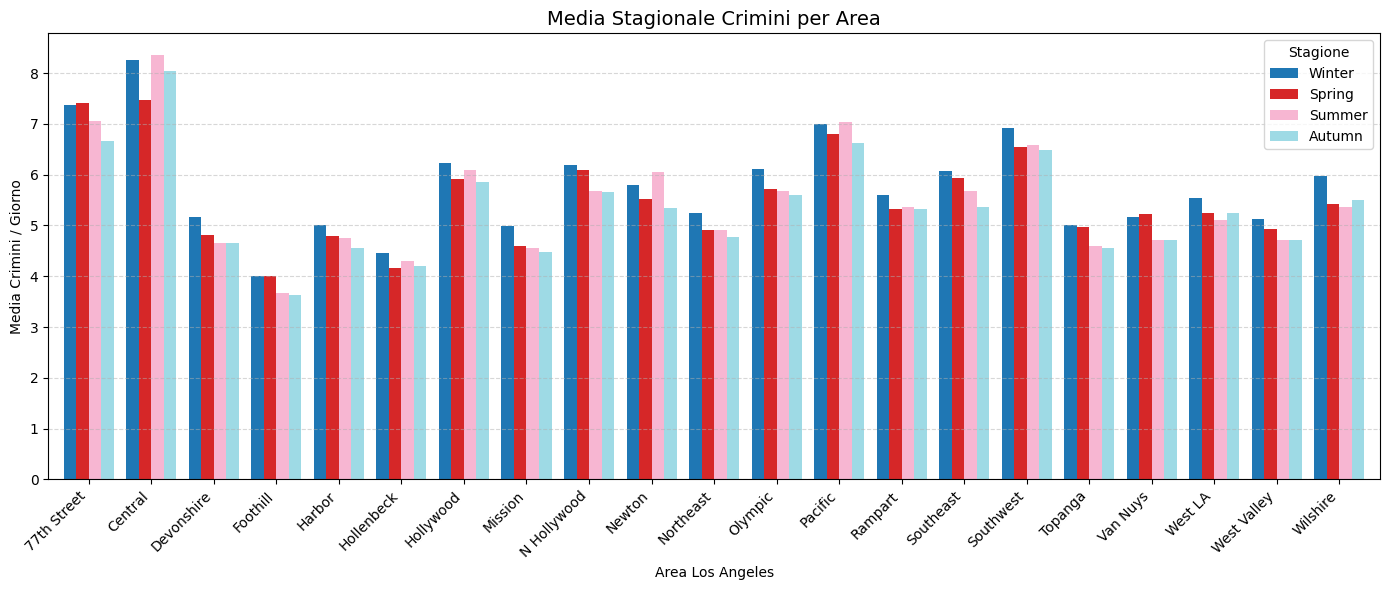

ANALISI: Aree con picco di criminalità stagionale

Distribuzione stagionale dei picchi:
- Winter: 16 aree (76.2%)
- Summer: 3 aree (14.3%)
- Spring: 2 aree (9.5%)

Top 5 Aree con picchi di stagionalità:
-   Wilshire -> Picco in Winter (+7.2%)
-    Mission -> Picco in Winter (+7.2%)
- Devonshire -> Picco in Winter (+7.2%)
-     Newton -> Picco in Summer (+6.7%)
-  Northeast -> Picco in Winter (+5.8%)


In [9]:
query = f'''
from(bucket: "{bucket}")
    |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["_field"] == "dr_no")

    // 1. Raggruppa per Area e Stagione
    |> group(columns: ["area_name", "season"])

    // 2. Conta i crimini giornalieri (importante: createEmpty: true)
    |> aggregateWindow(every: 1d, fn: count, createEmpty: true)

    // 3. Riempie i giorni senza crimini con 0
    |> fill(value: 0)

    // 4. Calcola la media dei crimini giornalieri
    |> mean()

    // 5. Unifica in un'unica tabella per facilitare Pandas e mantiene colonne utili
    |> group()
    |> keep(columns: ["area_name", "season", "_value"])
'''

start_time = time.time()
df = query_api.query_data_frame(query)
print(f"Tempo query: {time.time() - start_time:.2f}s")

# Gestione output lista
if isinstance(df, list):
    df = pd.concat(df)

# Rinomina la colonna valore
df = df.rename(columns={'_value': 'daily_avg'})

# Pivot per il grafico
pivot = df.pivot(index='area_name', columns='season', values='daily_avg')

# Ordina le colonne delle stagioni in modo logico
order = ['Winter', 'Spring', 'Summer', 'Autumn']
pivot = pivot[[s for s in order if s in pivot.columns]]

# --- GRAFICO ---
fig, ax = plt.subplots(figsize=(14, 6))
pivot.plot(kind='bar', ax=ax, width=0.8, colormap='tab20')
ax.set_title('Media Stagionale Crimini per Area', fontsize=14)
ax.set_ylabel('Media Crimini / Giorno')
ax.set_xlabel('Area Los Angeles')
ax.legend(title='Stagione')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("ANALISI: Aree con picco di criminalità stagionale\n")

seasonal_peaks = []
for area in pivot.index:
    # Recupera i valori della riga
    row_data = pivot.loc[area]
    
    max_val = row_data.max()    # Valore del picco
    mean_val = row_data.mean()  # Valore medio annuale (baseline)
    
    # (Max - Media) / Media
    # Indica di quanto il picco supera la normalità
    peak_intensity = (max_val - mean_val) / mean_val * 100 
    
    max_season = row_data.idxmax()
    
    seasonal_peaks.append({
        'Area': area, 
        'Stagione': max_season,
        'Intensita': peak_intensity
    })

# Crea DataFrame e ordina dal più alto al più basso
df_peaks = pd.DataFrame(seasonal_peaks).sort_values('Intensita', ascending=False)

# Statistica generale
print("Distribuzione stagionale dei picchi:")
season_counts = df_peaks['Stagione'].value_counts()
for season, count in season_counts.items():
    pct = count / len(df_peaks) * 100
    print(f"- {season}: {count} aree ({pct:.1f}%)")

# Top 5
print(f"\nTop 5 Aree con picchi di stagionalità:")
for _, row in df_peaks.head(5).iterrows():
    print(f"- {row['Area']:>10} -> Picco in {row['Stagione']} (+{row['Intensita']:.1f}%)")

### Query 2: Distribuzione Crimini Giorno vs Notte (Luglio 2023)

>per un mese a scelta, calcolare la distribuzione delle categorie di crimine (parte 1 o 2) per diverse fasce orarie (diurna/notturna) e visualizzare il risultato in un grafico a barre; i crimini violenti sono maggiormente distribuiti di notte?

Tempo query: 0.22s


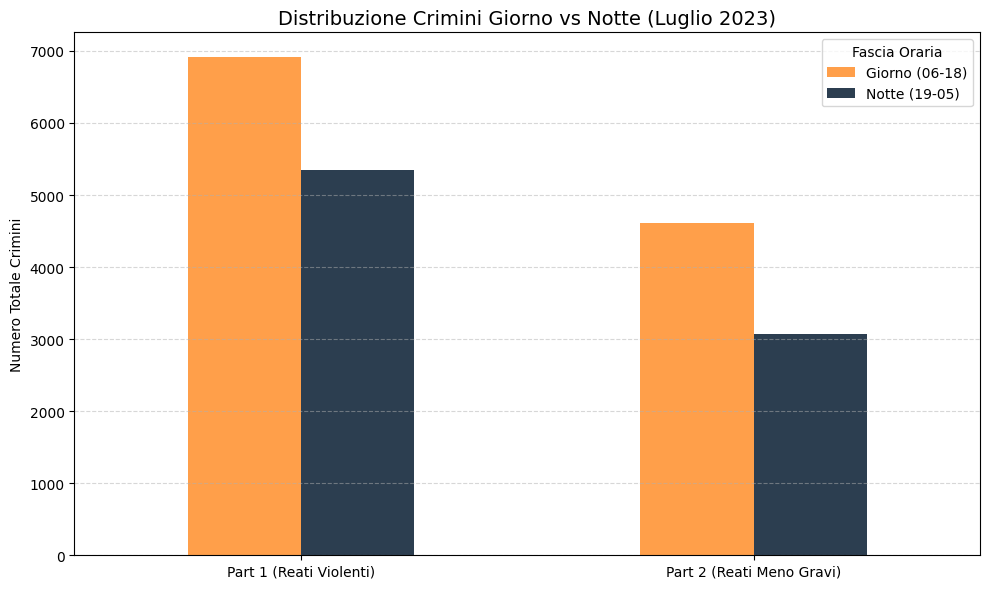

ANALISI: I crimini violenti sono distribuiti più di notte?

CATEGORIA                 | NOTTE    | GIORNO   | % NOTTE 
-------------------------------------------------------
Part 1 (Reati Violenti)   | 5346     | 6912     | 43.6%
Part 2 (Reati Meno Gravi) | 3067     | 4610     | 40.0%


In [10]:
query = f'''
from(bucket: "{bucket}")
  |> range(start: 2023-07-01T00:00:00Z, stop: 2023-07-31T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crime_report")
  |> filter(fn: (r) => r["_field"] == "dr_no")
  |> group(columns: ["part", "time_period"])
  |> count()
  |> group() 
  |> keep(columns: ["part", "time_period", "_value"])
'''

start_time = time.time()
df = query_api.query_data_frame(query)
print(f"Tempo query: {time.time() - start_time:.2f}s")

day_label = 'Giorno (06-18)'
night_label = 'Notte (19-05)'

if isinstance(df, list):
    df = pd.concat(df)

# Mappatura etichette
df['Category'] = df['part'].map({'1': 'Part 1 (Reati Violenti)', '2': 'Part 2 (Reati Meno Gravi)'})
df['Period'] = df['time_period'].map({'Day': day_label, 'Night': night_label})

# Pivot Table (Indice=Categoria, Colonne=Periodo)
pivot = df.pivot(index='Category', columns='Period', values='_value').fillna(0)

# Riordina colonne e righe per coerenza
cols_order = [day_label, night_label]
pivot = pivot[[c for c in cols_order if c in pivot.columns]]
pivot = pivot.sort_index()

# Visualizzazione
fig, ax = plt.subplots(figsize=(10, 6))
pivot.plot(kind='bar', ax=ax, color=['#FF9F4A', '#2C3E50'], rot=0)

ax.set_title('Distribuzione Crimini Giorno vs Notte (Luglio 2023)', fontsize=14)
ax.set_ylabel('Numero Totale Crimini')
ax.set_xlabel('')
ax.legend(title='Fascia Oraria')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Analisi
print("ANALISI: I crimini violenti sono distribuiti più di notte?\n")

# Calcolo percentuali
pivot['Totale'] = pivot.sum(axis=1)
pivot['% Notte'] = (pivot[night_label] / pivot['Totale']) * 100

# Visualizza tabella dati
print(f"{'CATEGORIA':<25} | {'NOTTE':<8} | {'GIORNO':<8} | {'% NOTTE':<8}")
print("-" * 55)
for idx, row in pivot.iterrows():
    print(f"{idx:<25} | {int(row[night_label]):<8} | {int(row[day_label]):<8} | {row['% Notte']:.1f}%")

### Query 3: Giornata con picco massimo di Crimini Violenti per Area

>identificare per ogni area la giornata con il maggior numero di crimini violenti e visualizzare il risultato un una tabella (area, data, conteggio); in quali mesi si concentrano i picchi più elevati?

In [11]:
query = f'''
from(bucket: "{bucket}")
    |> range(start: 2020-01-01T00:00:00Z, stop: 2025-11-30T23:59:59Z)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["part"] == "1") // Filtra solo crimini violenti/gravi
    |> filter(fn: (r) => r["_field"] == "dr_no")
    |> aggregateWindow(every: 1d, fn: count, createEmpty: false)
    |> group(columns: ["area_name"])
    |> max()
    |> group()
    |> keep(columns: ["area_name", "_time", "_value"])
'''

start_time = time.time()
df = query_api.query_data_frame(query)
print(f"Tempo query: {time.time() - start_time:.2f}s")

if isinstance(df, list):
    df = pd.concat(df)

# Rinomina colonne
df = df.rename(columns={'area_name': 'Area', '_value': 'Crimini Violenti'})

# Conversione Data
df['Data'] = pd.to_datetime(df['_time']).dt.date

# Ordinamento per numero di crimini (dal più grave al meno grave)
df = df.sort_values('Crimini Violenti', ascending=False)

# Selezione colonne
display_table = df[['Area', 'Data', 'Crimini Violenti']]

# Tabella
print("\nGiornata di picco per ogni Area\n")
print(display_table.to_string(index=False))

# Analisi picchi mensili
print("\nANALISI: In quali mesi si concentrano i picchi?\n")


# Estrai il mese dalla data del picco
# Uso di dt.month_name() per avere il nome completo
peak_months = pd.to_datetime(df['Data']).dt.month_name()

# Conta le occorrenze
month_counts = peak_months.value_counts()

print("Distribuzione dei picchi per mese:")
for month, count in month_counts.items():
    pct = count / len(df) * 100
    # Barra grafica
    bar = '█' * int(pct / 2) 
    print(f"   {month:<10}: {count:>2} aree ({pct:>5.1f}%)  {bar}")

Tempo query: 12.91s

Giornata di picco per ogni Area

       Area       Data  Crimini Violenti
  Southwest 2023-08-07                51
   Wilshire 2020-05-31                40
    Mission 2020-11-09                29
 Devonshire 2022-02-06                21
    Topanga 2021-09-24                18
    Central 2020-05-30                16
   Foothill 2020-08-22                13
     Newton 2022-02-27                13
  Southeast 2022-03-19                12
    Rampart 2024-09-11                12
  Northeast 2023-11-12                12
     Harbor 2020-09-09                12
 Hollenbeck 2021-05-12                11
    West LA 2020-03-27                11
West Valley 2024-10-13                11
  Hollywood 2022-02-19                10
77th Street 2023-06-29                10
    Pacific 2021-09-07                 8
    Olympic 2023-05-23                 7
N Hollywood 2020-12-23                 7
   Van Nuys 2024-04-08                 6

ANALISI: In quali mesi si concentrano i pic

### Query 4: Età media vittime per categoria e anno

>calcolare, per ogni categoria di crimine e per ogni anno, l’età media delle vittime

Tempo query: 17.88s
Età Media Vittime per gravità e anno

Anno      Part 1 (Gravi)        Part 2 (Minori)       
-------------------------------------------------------
2020      39.8                  39.5                  
2021      39.6                  39.6                  
2022      39.5                  39.3                  
2023      39.7                  39.5                  
2024      38.6                  39.5                  
2025      24.1                  23.2                  


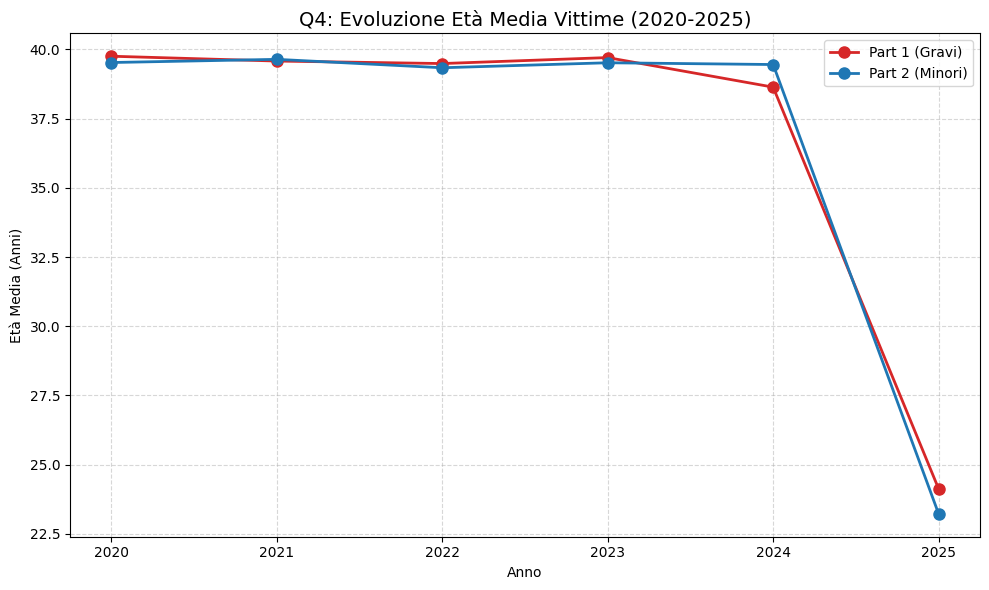

In [12]:
query = f'''
from(bucket: "{bucket}")
    |> range(start: 2020-01-01T00:00:00Z, stop: 2025-12-31T23:59:59Z)
    |> filter(fn: (r) => r["_measurement"] == "crime_report")
    |> filter(fn: (r) => r["_field"] == "vict_age")
    |> group(columns: ["part"])

    // gli anni vengono aggregati come 01-01-2020 01-01-2021 e etichettati come 2021, per evitare etichetta con anno iniziale corretto (2020) 
    // timeSrc: "_start" per etichettare gli anni 
    |> aggregateWindow(every: 1y, fn: mean, timeSrc: "_start")
    |> group()
    |> keep(columns: ["part", "_time", "_value"])
'''

start_time = time.time()
df = query_api.query_data_frame(query)
print(f"Tempo query: {time.time() - start_time:.2f}s")

if isinstance(df, list):
    df = pd.concat(df)

# Preparazione Dati
df['Anno'] = pd.to_datetime(df['_time']).dt.year
df['Part_Label'] = df['part'].map({'1': 'Part 1 (Gravi)', '2': 'Part 2 (Minori)'})

pivot = df.pivot_table(index='Anno', columns='Part_Label', values='_value', aggfunc='mean')

print("Età Media Vittime per gravità e anno\n")

# Header dinamico
cols = pivot.columns.tolist()
header = f"{'Anno':<10}" + "".join([f"{c:<22}" for c in cols])
print(header)
print("-" * 55)

for year, row in pivot.iterrows():
    row_str = f"{year:<10}" + "".join([f"{val:<22.1f}" if pd.notna(val) else f"{'N/A':<22}" for val in row])
    print(row_str)

# Grafico
fig, ax = plt.subplots(figsize=(10, 6))
colors = {'Part 1 (Gravi)': '#d62728', 'Part 2 (Minori)': '#1f77b4'}

for col in pivot.columns:
    color = colors.get(col, None)
    ax.plot(pivot.index, pivot[col], marker='o', linewidth=2, markersize=8, label=col, color=color)

ax.set_title('Q4: Evoluzione Età Media Vittime (2020-2025)', fontsize=14)
ax.set_xlabel('Anno')
ax.set_ylabel('Età Media (Anni)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xticks(pivot.index) # Forza anni interi asse X
plt.tight_layout()
plt.show()

Richiesta rimossa dal professore:
>Rieseguire tutte le query sopra filtrando per singola stagione (season). Misurare e confrontare i tempi di risposta per ciascun caso (query globali vs. stagionali).

## 3. Clustering Incrementale

Individuare pattern di criminalità ricorrenti nelle diverse aree di Los Angeles e verificare se questi profili sono cambiati significativamente nel periodo 2020-2025.

In base all'analisi preliminare (Silhouette Score e Metodo del Gomito), è stato selezionato **K=3** come numero ottimale di cluster per distinguere efficacemente tra aree a basso rischio, rischio standard e hotspot critici.

### 3.1 Estrazione Dati e Feature Engineering

In [4]:
def get_crime_features(client, bucket):
    """
    Estrae le feature aggregate da InfluxDB in un unico passaggio.
    Ritorna un DataFrame pronto per lo streaming.
    """
    
    query = f'''
    from(bucket: "{bucket}")
        |> range(start: 2020-01-01T00:00:00Z, stop: 2025-12-31T23:59:59Z)
        |> filter(fn: (r) => r["_measurement"] == "crime_report")
        |> filter(fn: (r) => r["_field"] == "dr_no")
        |> group(columns: ["area_name", "season", "part", "weapon_flag", "time_period"])
        // timeSrc="_start" assegna il dato all'inizio dell'anno
        |> aggregateWindow(every: 1y, fn: count, createEmpty: false, timeSrc: "_start")
        |> group()
        |> keep(columns: ["area_name", "season", "part", "weapon_flag", "time_period", "_time", "_value"])
    '''
    
    start_time = time.time()
    try:
        df_raw = client.query_api().query_data_frame(query)
        if isinstance(df_raw, list):
            df_raw = pd.concat(df_raw)
            
        if df_raw.empty:
            print("Nessun dato trovato.")
            return pd.DataFrame()

        # Feature Engineering
        df_raw['Year'] = pd.to_datetime(df_raw['_time']).dt.year
        df_raw = df_raw.rename(columns={'_value': 'count'})

        # Pivot & Aggregazione
        df_features = df_raw.groupby(['area_name', 'season', 'Year']).apply(
            lambda x: pd.Series({
                'total': x['count'].sum(),
                'weapon': x[x['weapon_flag'].astype(str) == 'True']['count'].sum(),
                'night': x[x['time_period'] == 'Night']['count'].sum(),
                'violent': x[x['part'].astype(str) == '1']['count'].sum()
            })
        ).reset_index()

        # Calcolo Percentuali
        df_features['pct_weapon'] = df_features['weapon'] / df_features['total'] * 100
        df_features['pct_night'] = df_features['night'] / df_features['total'] * 100
        df_features['pct_violent'] = df_features['violent'] / df_features['total'] * 100
        
        # Ordinamento Stream (Anno -> Stagione -> Area)
        df_features = df_features.sort_values(['Year', 'season', 'area_name']).reset_index(drop=True)
        
        print(f"Query completata in {time.time() - start_time:.2f}s")
        print(f"\nDataset pronto: {len(df_features)} record (Area x Stagione x Anno)")
        return df_features

    except Exception as e:
        print(f"Errore nella query: {e}")
        return pd.DataFrame()

# Esecuzione
df_features = get_crime_features(client, bucket)
if not df_features.empty:
    print(df_features.head(3).to_string(index=False))

Query completata in 27.02s

Dataset pronto: 444 record (Area x Stagione x Anno)
  area_name season  Year  total  weapon  night  violent  pct_weapon  pct_night  pct_violent
77th Street Autumn  2020   3261    1697   1441     1851   52.039252  44.188899    56.761730
    Central Autumn  2020   2705    1224   1158     1598   45.249538  42.809612    59.075786
 Devonshire Autumn  2020   1875     534    661     1083   28.480000  35.253333    57.760000


### 3.2 Training Online del Modello

In [5]:
feature_cols = ['total', 'pct_weapon', 'pct_night', 'pct_violent']
n_clusters = 3  # Scelto basandosi sul Silhouette Score ottimale

# Pipeline: Scaler Dinamico + KMeans Incrementale
model = compose.Pipeline(
    preprocessing.StandardScaler(),
    cluster.KMeans(n_clusters=n_clusters, seed=42)
)

cluster_assignments = []

# Stream Processing
for idx, row in df_features.iterrows():
    x = row[feature_cols].to_dict()
    model.learn_one(x)          # Apprendimento
    c_id = model.predict_one(x) # Predizione
    
    res = row.to_dict()
    res['Cluster'] = c_id
    cluster_assignments.append(res)

df_results = pd.DataFrame(cluster_assignments)
print("Training completato.")
print(f"Distribuzione Cluster:\n{df_results['Cluster'].value_counts().sort_index()}")

Training completato.
Distribuzione Cluster:
Cluster
0    121
1    168
2    155
Name: count, dtype: int64


### 3.3 Analisi dei Profili dei Cluster

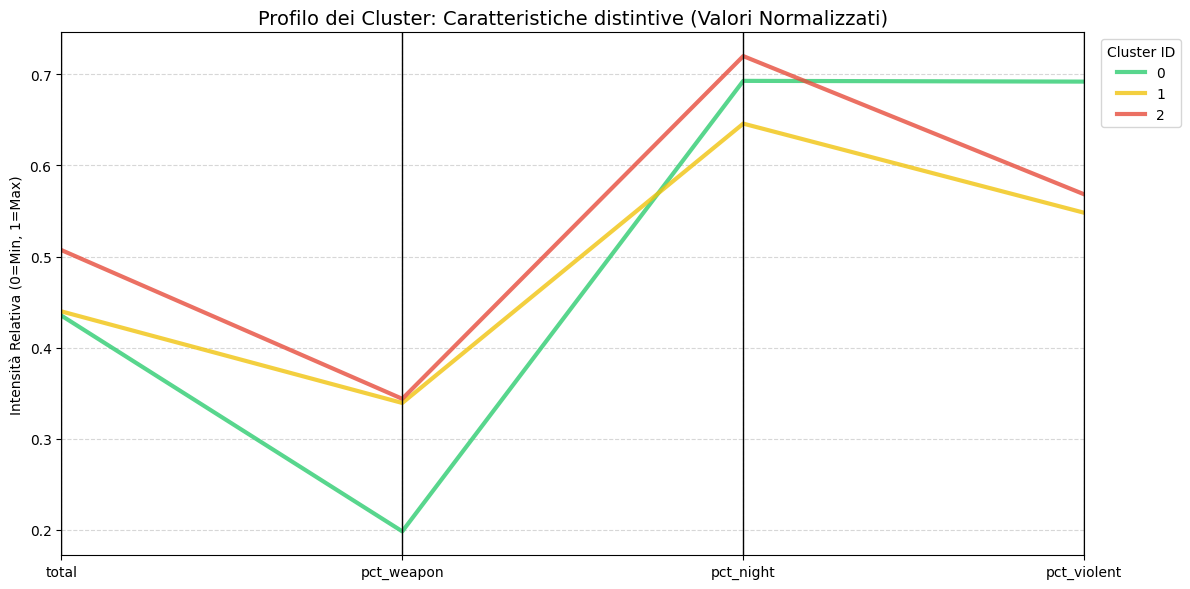

Valori medi reali (Centroidi):
           total  pct_weapon  pct_night  pct_violent
Cluster                                             
0        2127.32       19.83      39.59        69.21
1        2149.78       33.93      36.91        54.81
2        2478.59       34.39      41.15        56.83


In [6]:
# Calcolo Centroidi
centroids = df_results.groupby('Cluster')[feature_cols].mean()

# Normalizzazione Min-Max (solo per visualizzazione pulita)
centroids_norm = (centroids - df_results[feature_cols].min()) / (df_results[feature_cols].max() - df_results[feature_cols].min())

# Grafico
plt.figure(figsize=(12, 6))
pd.plotting.parallel_coordinates(
    centroids_norm.reset_index(), 
    'Cluster', 
    color=['#2ecc71', '#f1c40f', '#e74c3c'],
    linewidth=3,
    alpha=0.8
)

plt.title('Profilo dei Cluster: Caratteristiche distintive (Valori Normalizzati)', fontsize=14)
plt.ylabel('Intensità Relativa (0=Min, 1=Max)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Cluster ID', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

print("Valori medi reali (Centroidi):")
print(centroids.round(2))

**Interpretazione Cluster:**
* **Cluster 0 (Verde):** Basso uso di armi, ma alta violenza fisica ("Violenza Domestica/Aggressioni").
* **Cluster 1 (Giallo):** Valori intermedi ("Criminalità Standard").
* **Cluster 2 (Rosso):** Alto volume e alto uso di armi ("Hotspots Critici").

### Distribuzione Aree Los Angeles nei Cluster

(capire se serve)

In [7]:
# Tabella Aree per Cluster (ultimo anno disponibile)
latest_year = df_results['Year'].max()
df_latest = df_results[df_results['Year'] == latest_year]

# Raggruppa le aree per cluster (moda del cluster per area nella stagione più recente)
area_clusters = df_latest.groupby('area_name')['Cluster'].agg(lambda x: x.mode()[0]).reset_index()
area_clusters.columns = ['Area', 'Cluster']
area_clusters = area_clusters.sort_values(['Cluster', 'Area'])

# Etichette descrittive
cluster_labels = {
    0: "Cluster 0 - Basso Rischio",
    1: "Cluster 1 - Rischio Standard", 
    2: "Cluster 2 - Hotspot Critici"
}

for c_id in sorted(area_clusters['Cluster'].unique()):
    areas = area_clusters[area_clusters['Cluster'] == c_id]['Area'].tolist()
    label = cluster_labels.get(c_id, f"Cluster {c_id}")
    
    print(f"\n{label} ({len(areas)} aree):")
    print("-" * 40)
    for area in areas:
        print(f"- {area}")


Cluster 0 - Basso Rischio (2 aree):
----------------------------------------
- Southwest
- Wilshire

Cluster 1 - Rischio Standard (13 aree):
----------------------------------------
- Devonshire
- Foothill
- Harbor
- Hollenbeck
- Mission
- N Hollywood
- Olympic
- Pacific
- Rampart
- Topanga
- Van Nuys
- West LA
- West Valley

Cluster 2 - Hotspot Critici (5 aree):
----------------------------------------
- 77th Street
- Central
- Newton
- Northeast
- Southeast


### 3.4 Evoluzione Temporale (2020-2025)

Il grafico seguente mostra la percentuale di aree appartenenti a ciascun cluster nel corso del tempo. Questo ci permette di rispondere alla domanda: **"I pattern cambiano significativamente?"**

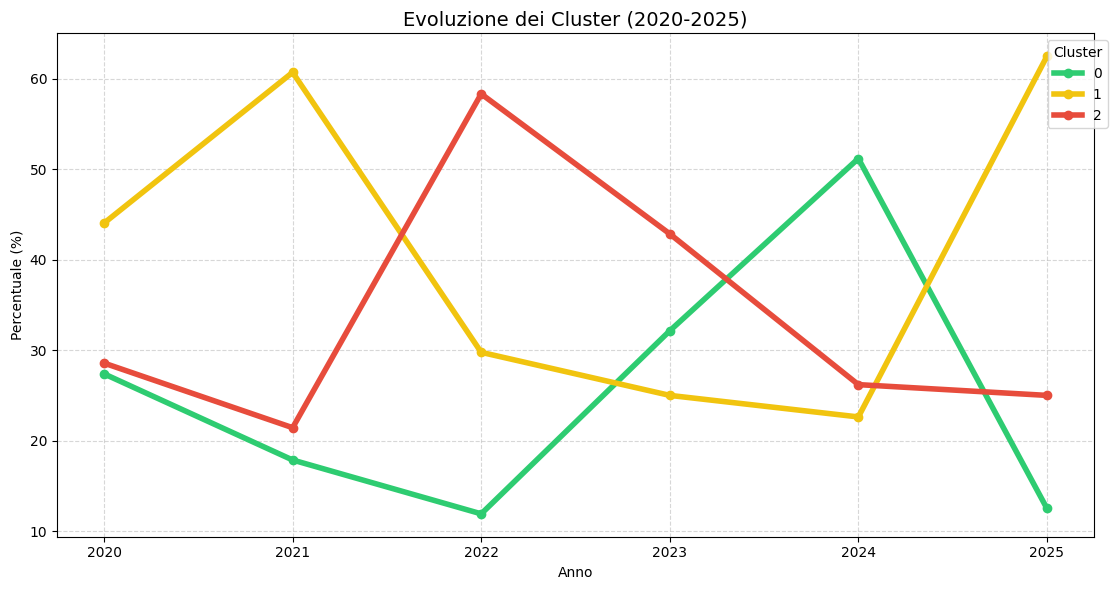

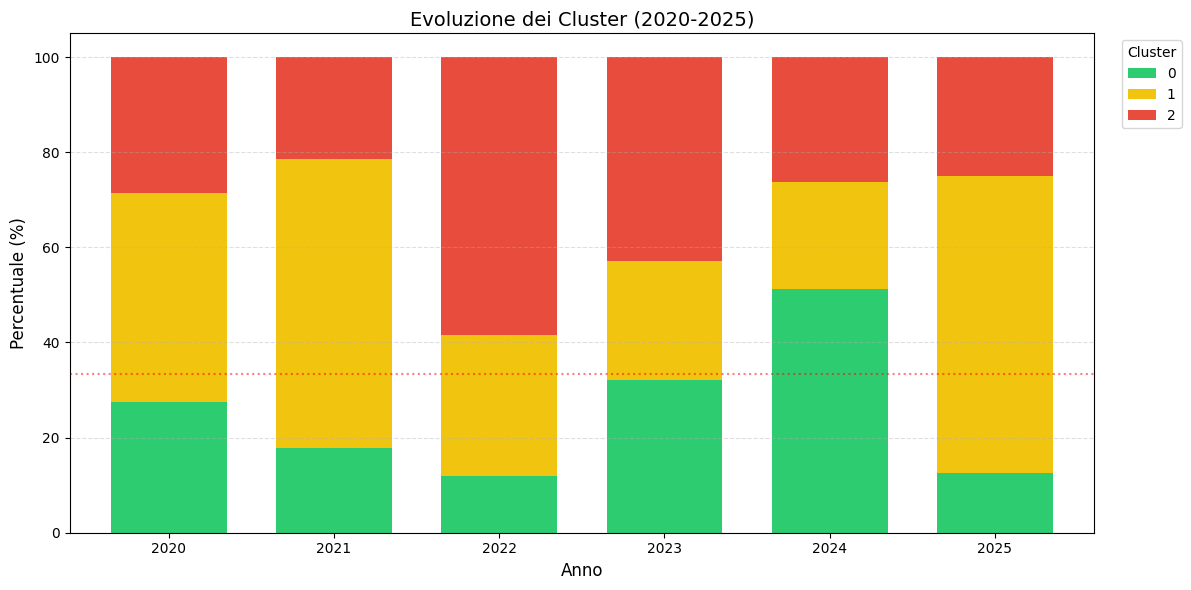

Confronto tra 2020 e 2025:
Cluster 0: 27.4% -> 12.5% (DIMINUITO)
Cluster 1: 44.0% -> 62.5% (AUMENTATO)
Cluster 2: 28.6% -> 25.0% (STABILE)


In [8]:
trend_data = df_results.groupby(['Year', 'Cluster']).size().unstack(fill_value=0)
trend_pct = trend_data.div(trend_data.sum(axis=1), axis=0) * 100

# Grafico a Linee
plt.figure(figsize=(12, 6))
colors = ['#2ecc71', '#f1c40f', '#e74c3c']

for i, c_id in enumerate(trend_pct.columns):
    plt.plot(trend_pct.index, trend_pct[c_id], 
            marker='o', linewidth=4, label=c_id, color=colors[i])

plt.title('Evoluzione dei Cluster (2020-2025)', fontsize=14)
plt.xlabel('Anno')
plt.ylabel('Percentuale (%)')
plt.legend(bbox_to_anchor=(1.02, 1), title="Cluster")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(trend_pct.index)
plt.tight_layout()
plt.show()

# Grafico a Barre Impilate
fig, ax = plt.subplots(figsize=(12, 6))
trend_pct.plot(
    kind='bar', 
    stacked=True, 
    ax=ax,
    color=colors,
    width=0.7
)
ax.set_title(f'Evoluzione dei Cluster (2020-2025)', fontsize=14)
ax.set_xlabel('Anno', fontsize=12)
ax.set_ylabel('Percentuale (%)', fontsize=12)
ax.legend(title='Cluster', bbox_to_anchor=(1.02, 1))
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.xticks(rotation=0)

# Aggiungi linea di riferimento al 33.3% per ogni cluster ideale
ax.axhline(y=33.3, color='red', linestyle=':', alpha=0.5, label='Distribuzione uniforme')
plt.tight_layout()
plt.show()

# Analisi Testuale
print("Confronto tra 2020 e 2025:")
start = trend_pct.iloc[0]
end = trend_pct.iloc[-1]

for c_id in trend_pct.columns:
    diff = end[c_id] - start[c_id]
    trend = "AUMENTATO" if diff > 5 else "DIMINUITO" if diff < -5 else "STABILE"
    print(f"Cluster {c_id}: {start[c_id]:.1f}% -> {end[c_id]:.1f}% ({trend})")

### Conclusioni Analisi Clustering

L'analisi con **K=3** ha rivelato una dinamica fondamentale non visibile con una semplice aggregazione:

1.  **Identificazione Hotspot:** Il **Cluster 2 (Linea Rossa)** identifica le aree critiche caratterizzate da alto volume e alta incidenza di crimini armati.
2.  **Dinamica Temporale:** Si osserva un picco di criticità nel periodo post-pandemico (2021-2022), seguito da un **drastico calo nel 2024-2025**.
3.  **Shift Strutturale:** Nel 2025, la maggior parte delle aree che erano classificate come "Critiche" (Cluster 2) sono migrate verso il **Cluster 1 (Standard)**, indicando una generale riduzione dell'intensità criminale e dell'uso di armi a Los Angeles.